# 02 · Before and after: preserve the pairs
**Insight:** people start at different levels. Comparing each person with themselves can reveal a change hidden by those differences.

We simulate task-completion times for **30 people measured twice**. A paired t-test tests the mean of the 30 individual differences (after − before). Welch’s independent t-test is included to demonstrate what happens when we ignore the known pairing—not as an equally appropriate analysis of this design.

**Assumptions:** correctly matched numerical measurements, independent people, and approximately normal differences for small-sample paired inference. Here differences are normal by construction. Measurements within a person are dependent; separate people are independent. All tests are two-sided at 5%. Before/after change alone does not establish a causal treatment effect.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261126
REPETITIONS = 20_000
N = 30
ALPHA = 0.05
NOISE_SD = 5
CHANGE = -3  # three minutes faster after; null check uses zero
OUT = Path("outputs/02-paired-before-after")
OUT.mkdir(parents=True, exist_ok=True)
scenarios = [("Similar starting levels", 2), ("Different starting levels", 15)]
display(pd.DataFrame([dict(scenario=name, people=N, baseline_sd=sd,
    measurement_noise_sd=NOISE_SD, true_change=CHANGE,
    population_correlation=sd**2/(sd**2+NOISE_SD**2)) for name, sd in scenarios]).round(3))

,scenario,people,baseline_sd,measurement_noise_sd,true_change,population_correlation
0,Similar starting levels,30,2,5,-3,0.138
1,Different starting levels,30,15,5,-3,0.900


## 1 · Same people, different starting levels
Model: before = 60 + person’s baseline offset + before noise; after = 60 + **the same offset** + change + after noise. Offsets and both noise terms are independent normal draws. This is illustrative simulated data, not observed task times; normal tails are not truncated.

Only the spread of baseline offsets changes between scenarios. Individual differences cancel that offset: after − before = change + after noise − before noise. Their population SD is √(5² + 5²) = **7.07 minutes** in both scenarios. Higher baseline spread produces higher positive before/after correlation; it does not make individual changes less noisy.

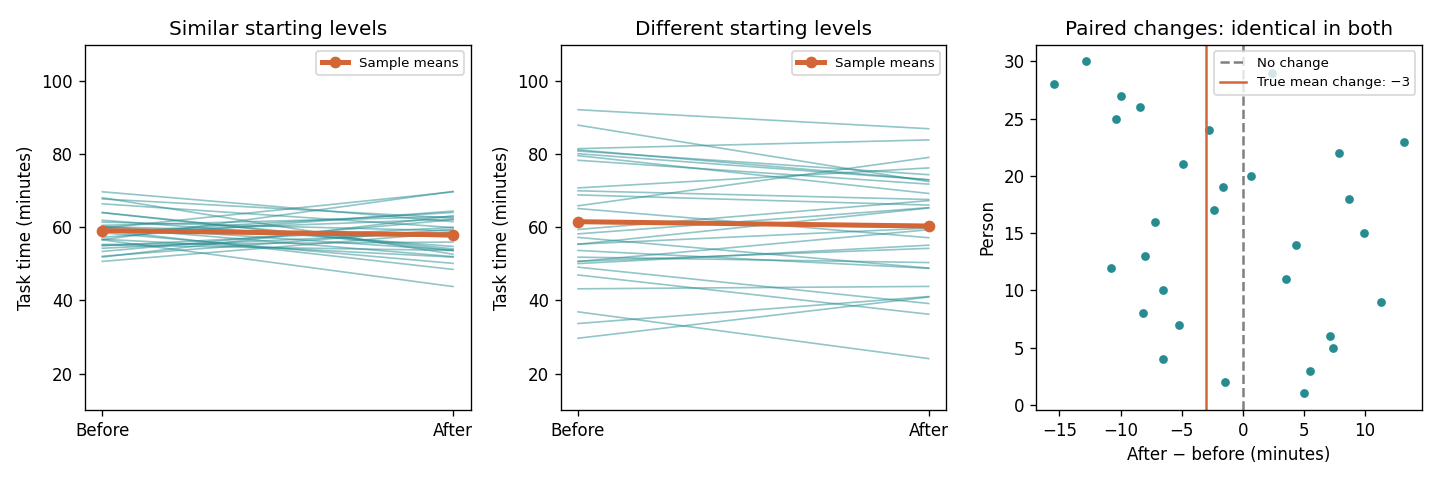

In [2]:
rng_example = np.random.default_rng(SEED)
z_baseline = rng_example.normal(size=N)
before_noise = rng_example.normal(0, NOISE_SD, N)
after_noise = rng_example.normal(0, NOISE_SD, N)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
examples = []
for ax, (name, baseline_sd) in zip(axes[:2], scenarios):
    before = 60 + baseline_sd*z_baseline + before_noise
    after = 60 + baseline_sd*z_baseline + CHANGE + after_noise
    for i in range(N):
        ax.plot([0, 1], [before[i], after[i]], color="#268c91", alpha=.5, linewidth=1)
        examples.append(dict(scenario=name, person=i+1, before=before[i], after=after[i], difference=after[i]-before[i]))
    ax.plot([0, 1], [before.mean(), after.mean()], color="#d36636", linewidth=3, marker="o", label="Sample means")
    ax.set(xticks=[0, 1], xticklabels=["Before", "After"], title=name, ylabel="Task time (minutes)", ylim=(10, 110))
    ax.legend(fontsize=8)
differences = CHANGE + after_noise-before_noise
axes[2].scatter(differences, np.arange(1, N+1), color="#268c91", s=18)
axes[2].axvline(0, color="gray", linestyle="--", label="No change")
axes[2].axvline(CHANGE, color="#d36636", label="True mean change: −3")
axes[2].set(title="Paired changes: identical in both", xlabel="After − before (minutes)", ylabel="Person")
axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "paired_samples.png", dpi=160)
plt.show()
pd.DataFrame(examples).to_csv(OUT / "example_pairs.csv", index=False)

## 2 · Detect real change, then check false alarms
Run 20,000 repetitions for a true −3-minute change (**power**) and a zero change (**false-positive rate**). Both tests see the same observations. Reuse baseline/noise draws across scenarios so differences reflect the baseline-spread setting; scenario results are therefore correlated.

Report rejection percentages with 95% Wilson Monte Carlo intervals, average estimated SE, true SE, and mean estimated change. These intervals describe simulation precision. No multiple-testing correction is applied: repetitions estimate each procedure’s performance, rather than seek a publishable discovery.

In [3]:
rng = np.random.default_rng(SEED + 1)
z = rng.normal(size=(REPETITIONS, N))
e_pre = rng.normal(0, NOISE_SD, (REPETITIONS, N))
e_post = rng.normal(0, NOISE_SD, (REPETITIONS, N))
rows, trials = [], []
true_se = np.sqrt(2*NOISE_SD**2/N)
for name, baseline_sd in scenarios:
    before = 60 + baseline_sd*z + e_pre
    for change in [CHANGE, 0]:
        after = 60 + baseline_sd*z + change + e_post
        d = after-before
        tests = {
            "Paired": (stats.ttest_rel(after, before, axis=1), d.std(axis=1, ddof=1)/np.sqrt(N)),
            "Ignoring pairs (Welch)": (stats.ttest_ind(after, before, axis=1, equal_var=False),
                 np.sqrt((after.var(axis=1, ddof=1)+before.var(axis=1, ddof=1))/N))
        }
        for test, (result, se) in tests.items():
            rejected = result.pvalue < ALPHA
            count = int(rejected.sum())
            ci = stats.binomtest(count, REPETITIONS).proportion_ci(method="wilson")
            rows.append(dict(scenario=name, test=test, true_change=change,
                metric="Power" if change else "False positives", repetitions=REPETITIONS,
                rejections=count, rejection_pct=100*rejected.mean(),
                mc_low_pct=100*ci.low, mc_high_pct=100*ci.high,
                mean_estimated_change=d.mean(axis=1).mean(), mean_estimated_se=se.mean(), true_se=true_se))
            trials.append(pd.DataFrame(dict(scenario=name, test=test, true_change=change,
                repetition=np.arange(REPETITIONS), mean_change=d.mean(axis=1), p_value=result.pvalue)))
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "metrics.csv", index=False)
pd.concat(trials, ignore_index=True).to_csv(OUT / "trials.csv", index=False)
display(summary.round(3))
# Checks of the paired calculation and controlled design.
assert np.isfinite(summary.select_dtypes("number")).all().all()
assert np.allclose(stats.ttest_rel(after, before, axis=1).pvalue,
                   stats.ttest_1samp(after-before, 0, axis=1).pvalue)
paired = summary[summary.test == "Paired"]
assert np.allclose(paired.iloc[:2].rejection_pct, paired.iloc[2:].rejection_pct)
assert np.allclose(paired.iloc[:2].mean_estimated_se, paired.iloc[2:].mean_estimated_se)

,scenario,test,true_change,metric,repetitions,rejections,rejection_pct,mc_low_pct,mc_high_pct,mean_estimated_change,mean_estimated_se,true_se
0,Similar starting levels,Paired,-3,Power,20000,12287,61.435,60.758,62.107,-3.007,1.280,1.291
1,Similar starting levels,Ignoring pairs (Welch),-3,Power,20000,11375,56.875,56.187,57.560,-3.007,1.385,1.291
2,Similar starting levels,Paired,0,False positives,20000,999,4.995,4.702,5.306,-0.007,1.280,1.291
3,Similar starting levels,Ignoring pairs (Welch),0,False positives,20000,666,3.330,3.090,3.588,-0.007,1.385,1.291
4,Different starting levels,Paired,-3,Power,20000,12287,61.435,60.758,62.107,-3.007,1.280,1.291
5,Different starting levels,Ignoring pairs (Welch),-3,Power,20000,12,0.060,0.034,0.105,-3.007,4.048,1.291
6,Different starting levels,Paired,0,False positives,20000,999,4.995,4.702,5.306,-0.007,1.280,1.291
7,Different starting levels,Ignoring pairs (Welch),0,False positives,20000,0,0.000,0.000,0.019,-0.007,4.048,1.291


## 3 · Pairing preserves the signal
**Left:** power to detect the known change; higher is better provided false positives stay controlled. **Right:** false alarms with no change; the intended rate is 5%. Zero observed false positives does not establish a zero underlying probability—the interval still has a positive upper bound.

Out[1]: 414


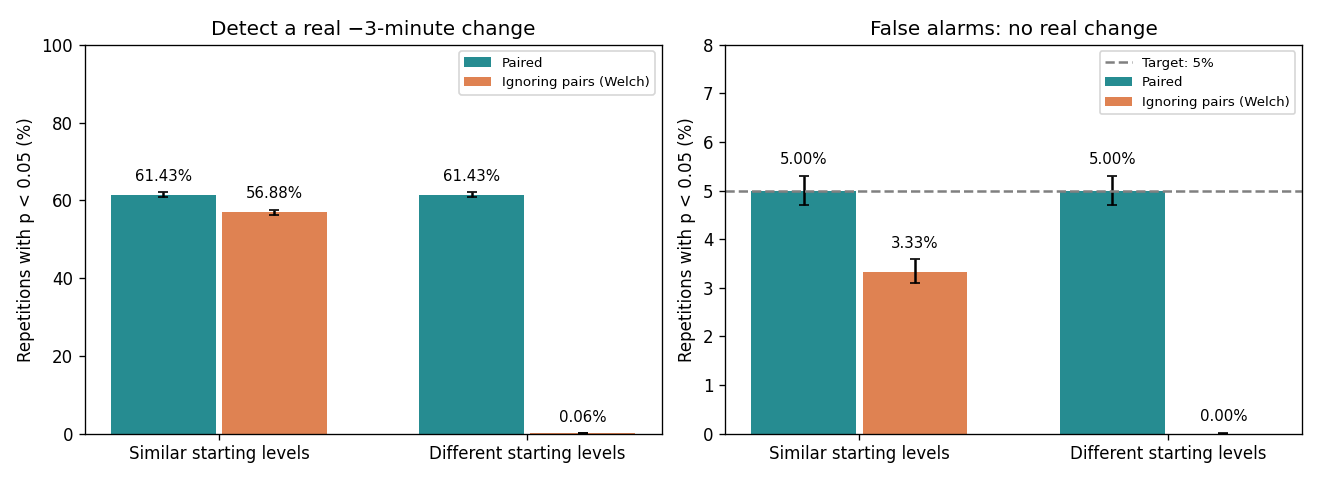

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(2)
for ax, metric in zip(axes, ["Power", "False positives"]):
    for test, offset, color in [("Paired", -.18, "#268c91"), ("Ignoring pairs (Welch)", .18, "#df8252")]:
        sub = summary[(summary.metric == metric) & (summary.test == test)]
        y = sub.rejection_pct.to_numpy()
        err = np.maximum(0, np.vstack([y-sub.mc_low_pct.to_numpy(), sub.mc_high_pct.to_numpy()-y]))
        bars = ax.bar(x+offset, y, .34, color=color, label=test, yerr=err, capsize=3)
        ax.bar_label(bars, labels=[f"{v:.2f}%" for v in y], padding=5, fontsize=9)
    ax.set_xticks(x, [s[0] for s in scenarios])
    ax.set_ylabel("Repetitions with p < 0.05 (%)")
    ax.set_title("Detect a real −3-minute change" if metric=="Power" else "False alarms: no real change")
    ax.set_ylim(0, 100 if metric=="Power" else 8)
    if metric == "False positives": ax.axhline(5, color="gray", linestyle="--", label="Target: 5%")
    ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(OUT / "power_and_false_positives.png", dpi=180)
plt.show()
settings = dict(seed=SEED, simulation_seed=SEED+1, repetitions=REPETITIONS, n_pairs=N,
    alpha=ALPHA, baseline_mean=60, noise_sd=NOISE_SD, changes=[CHANGE, 0], scenarios=scenarios,
    common_random_numbers=True, python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__)
(OUT / "settings.json").write_text(json.dumps(settings, indent=2))

## Takeaway
**The same people’s baseline differences cancel when we subtract before from after.** Paired power stays stable as baseline spread increases; ignoring pairs overstates uncertainty under this positive-correlation model and loses power. Both analyses estimate the same mean change; their uncertainty calculations differ.

The paired standard error uses SD(after − before)/√n. In general, Var(after − before) = Var(after) + Var(before) − 2 Cov(before, after). This simulation illustrates positive covariance, not a universal guarantee that pairing always reduces uncertainty. Treat pairing as a design fact, not a test chosen after inspecting significance. Negative covariance can make an independence analysis behave differently.

**Review prompt:** Why can before and after distributions overlap heavily even when individual changes provide evidence of a mean change?

## Website presentation brief
**Goal:** one insight, visually led, with compact explanation and optional depth.

1. **Question:** “Can a real change hide behind different starting points?”
2. **Setup:** Show matched before/after lines for 30 people. Label the shared person IDs and explain that 30 people produce 30 differences, not 60 independent observations. Switch between similar and different starting levels using the same vertical scale.
3. **Reveal:** Show the individual-change plot: baseline differences disappear. These example changes are identical across scenarios by construction; lines need not all move in the same direction.
4. **Evidence:** Lead with the power comparison, accompanied by the null false-alarm check. Read labels from saved metrics. Use consistent test colours, direct percentages, and visible Monte Carlo intervals. The two metric panels have intentionally different labelled scales; do not compare their bar heights across panels.
5. **Takeaway:** “People start at different levels. Comparing each person with themselves can reveal a change hidden by those differences.”

Keep assumptions, covariance formula, settings and limitations expandable. Explicitly label Welch’s here as **ignoring known pairs**, not a valid independent-group alternative for these data. This example concerns increased sensitivity, unlike notebook 01’s inflated false-alarm demonstration. Normal simulated data and a true −3-minute change are teaching settings, not real measurements or causal evidence. No website implementation is included.
